实验内容如下：   
- 1）使用sklearn中逻辑斯蒂回归模型对西瓜数据集3.0α进行分类，并对算法性能进行评估  
- 2）使用sklearn中支持向量机模型对西瓜数据集3.0α进行分类，并对算法性能进行评估  
- 3）自己编写算法实现对数几率回归，对西瓜数据集3.0α进行分类，并对算法性能进行评估  
- 4）自己编写算法实现线性判别分析，对西瓜数据集3.0α进行分类，并对算法性能进行评估  
- 5）不同算法分类结果的可视化和对比分析。  

## 一、逻辑斯蒂（Logistic）回归模型

### 1.数据预处理

In [16]:
import numpy as np
import pandas as pd

df = pd.read_csv('./res/watermelon_3_0_a.csv', encoding='gbk')
print(df.head())

X = df.iloc[:, 1:-1].values
print(X)
y = df.iloc[:,-1].map({'是':1, '否':0}).values
print(y)

   编号     密度    含糖率 好瓜
0   1  0.697  0.460  是
1   2  0.774  0.376  是
2   3  0.643  0.264  是
3   4  0.608  0.318  是
4   5  0.556  0.215  是
[[0.697 0.46 ]
 [0.774 0.376]
 [0.643 0.264]
 [0.608 0.318]
 [0.556 0.215]
 [0.403 0.237]
 [0.481 0.149]
 [0.437 0.211]
 [0.666 0.091]
 [0.243 0.267]
 [0.245 0.057]
 [0.343 0.099]
 [0.639 0.161]
 [0.657 0.198]
 [0.36  0.37 ]
 [0.593 0.042]
 [0.719 0.103]]
[1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0]


### 2.使用sklearn实现逻辑回归模型

Accuracy: 64.71%


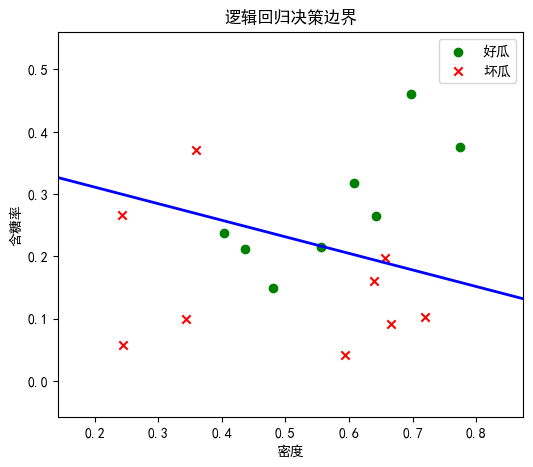

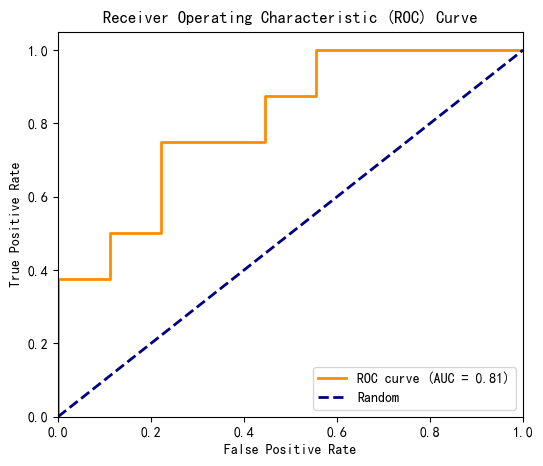

In [45]:
from sklearn.linear_model import LogisticRegression
# 创建逻辑回归模型对象
model = LogisticRegression(C=200)
# 训练模型
model.fit(X, y)
# 预测标签
predictions = model.predict(X)
# 计算准确率
accuracy = np.mean(predictions == y) * 100
print('Accuracy: {:.2f}%'.format(accuracy))




import matplotlib.pyplot as plt

# 绘制散点图（用原始未标准化的 X）
plt.figure(figsize=(6,5))
# 好瓜（y=1）用绿色圆点，坏瓜（y=0）用红色叉号
plt.scatter(X[y==1, 0], X[y==1, 1], c='g', marker='o', label='好瓜')
plt.scatter(X[y==0, 0], X[y==0, 1], c='r', marker='x', label='坏瓜')

# 生成网格点，用于绘制决策边界
x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# 预测网格点的类别概率（逻辑回归输出的是概率）
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)

# 画出决策边界（取概率=0.5的等高线）
plt.contour(xx, yy, Z, levels=[0.5], colors='blue', linewidths=2)
plt.xlabel('密度')
plt.ylabel('含糖率')
plt.title('逻辑回归决策边界')
plt.legend()
plt.show()



from sklearn.metrics import roc_curve, auc
# 获取预测为正类（好瓜）的概率
y_scores = model.predict_proba(X)[:, 1]

# 计算假正率（FPR）、真正率（TPR）及 AUC
fpr, tpr, thresholds = roc_curve(y, y_scores)
roc_auc = auc(fpr, tpr)

# 绘制 ROC 曲线
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

## 二、向量机模型

   编号     密度    含糖率 好瓜
0   1  0.697  0.460  是
1   2  0.774  0.376  是
2   3  0.643  0.264  是
3   4  0.608  0.318  是
4   5  0.556  0.215  是
SVM Accuracy: 94.12%


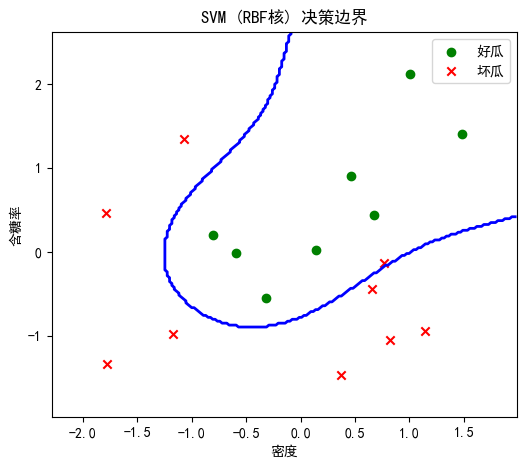

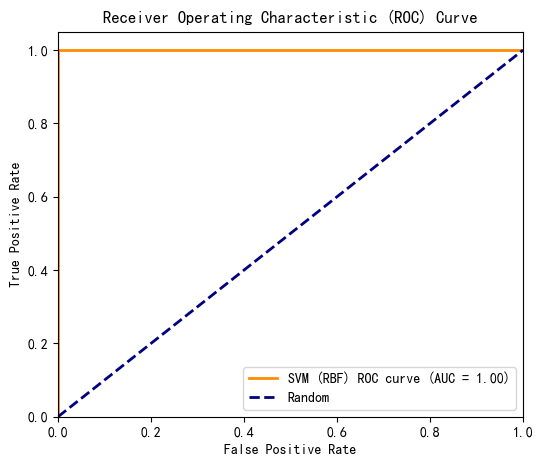

In [31]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# 1. 读取数据
df = pd.read_csv('./res/watermelon_3_0_a.csv', encoding='gbk')
print(df.head())

# 2. 提取特征和标签
#   假设第一列是编号，最后一列是标签，中间所有列为特征
X = df.iloc[:, 1:-1].values          # 特征（已包含数值和分类特征）
y = df.iloc[:, -1].map({'是': 1, '否': 0}).values   # 标签映射为 1/0

# 3. 特征标准化（SVM 对特征尺度敏感，逻辑回归不需要，但 SVM 建议做）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. 创建 SVM 模型（使用默认 RBF 核）
model = SVC(kernel='rbf', random_state=42)

# 5. 训练模型
model.fit(X_scaled, y)

# 6. 预测并计算准确率
predictions = model.predict(X_scaled)
accuracy = np.mean(predictions == y) * 100
print('SVM Accuracy: {:.2f}%'.format(accuracy))

import matplotlib.pyplot as plt

# 注意：SVM 训练时用了标准化后的 X_scaled，但绘图时希望坐标轴显示原始特征值
# 所以我们要用原始 X 画散点，但决策边界需要在标准化空间计算后再映射回原始坐标。
# 简便做法：直接对标准化后的数据画图（横纵轴都是标准化后的值），这样代码最简单。
# 如果你希望横纵轴显示原始特征值，需要额外做反向变换。下面提供最简版本（显示标准化后的坐标）。

X_scaled = scaler.transform(X)  # 保证使用与训练时相同的 scaler

plt.figure(figsize=(6,5))
plt.scatter(X_scaled[y==1, 0], X_scaled[y==1, 1], c='g', marker='o', label='好瓜')
plt.scatter(X_scaled[y==0, 0], X_scaled[y==0, 1], c='r', marker='x', label='坏瓜')

# 生成网格点（在标准化空间内）
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# 预测网格点的类别
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 画出决策边界（0/1 分类的边界即为 Z=0.5 的位置，但 SVM 输出是 0/1，所以用 levels=[0.5]）
plt.contour(xx, yy, Z, levels=[0.5], colors='blue', linewidths=2)
plt.xlabel('密度')
plt.ylabel('含糖率')
plt.title('SVM (RBF核) 决策边界')
plt.legend()
plt.show()

from sklearn.metrics import roc_curve, auc

# 获取决策函数值（正类距离）
y_scores = model.decision_function(X_scaled)

# 计算 ROC 曲线和 AUC
fpr, tpr, thresholds = roc_curve(y, y_scores)
roc_auc = auc(fpr, tpr)

# 绘制 ROC 曲线
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='SVM (RBF) ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

## 三、对数几率回归